[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roberthsu2003/PythonForDataAnalysis/blob/master/%E6%97%A5%E6%9C%9F%E5%92%8C%E6%99%82%E9%96%93/%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90/%E7%AF%84%E4%BE%8B_%E9%9B%BB%E8%B2%BB%E6%BC%B2%E4%BA%86%E5%A4%9A%E5%B0%91_%E7%A9%BA%E6%B1%99%E5%93%AA%E5%A4%A9%E6%9C%80%E5%9A%B4%E9%87%8D_%E6%99%82%E9%96%93%E5%BA%8F%E5%88%97.ipynb)

# 📅 電費漲了多少？空汙哪天最嚴重？用時間序列看懂變化

> 🎯 **情境**：「最近電費好像變貴了？」「這幾天空氣好差！」——這些感覺都跟**時間**有關。今天你手上有三份帶著時間的真實資料：八年的電費、一年的空氣品質、一個月的捷運人潮。你要學會把各種奇怪的日期格式（像民國年 `10701`）變成 pandas 看得懂的時間，再用 **resample、年增率、移動平均** 回答：**電費到底漲了多少？哪幾天的空汙特別嚴重？**

| 素材檔案 | 內容 |
| --- | --- |
| `台電住宅每戶平均用電與電費.csv` | 台電住宅每戶每月平均用電與電費（日期是**民國年月** `10701`） |
| `日空氣品質指標_近一年.csv` | 環境部近一年、全台 80 多個測站的每日 AQI |
| `臺北捷運各站分時進出量_202603.csv` | 臺北捷運 2026 年 3 月各站每小時進出站人次 |

| 📡 資料來源（政府資料開放平台） | 提供機關 | 下載日期 |
| --- | --- | --- |
| [台灣電力公司住宅用戶每月平均用電度數及電費](https://data.gov.tw/dataset/17062) | 台灣電力股份有限公司 | 2026-10-24 |
| [日空氣品質指標(AQI)](https://data.gov.tw/dataset/40507) | 環境部 | 2026-10-24 |
| [臺北捷運各站分時進出量統計](https://data.gov.tw/dataset/128506) | 臺北大眾捷運股份有限公司 | 2026-10-24 |

> ✅ 這些都是**真實的政府開放資料**，依「政府資料開放授權條款－第1版」使用。課堂上統一使用上表日期的快照，所以每個人跑出來的數字都一樣。

## 🗺️ 今日任務地圖

| 關卡 | 要回答的問題 |
| --- | --- |
| ⬜ 任務 1 | 民國年月 `10701` → 真正的日期 |
| ⬜ 任務 2 | 每戶一年要付多少電費？——`resample` |
| ⬜ 任務 3 | 今年比去年貴多少？——年增率 `pct_change(12)` |
| ⬜ 任務 4 | 空氣品質的「趨勢」與「異常日」——`rolling` |
| ⬜ 任務 5 | 捷運的日期與時段——`dt` 屬性 |
| ⬜ 任務 6 | 時區——國際合作夥伴要 UTC 時間 |

**怎麼用這本 Notebook**：從上到下按 `Shift + Enter` 一格一格執行。每個任務都會先講「你想知道什麼」，再給程式，最後用 💡 **看懂結果** 告訴你這個數字代表什麼。

In [1]:
# 📦 準備素材：在 Colab 開啟時，自動下載本章素材壓縮檔並解壓縮
#    （若是在自己電腦解壓縮後開啟，檔案已經在旁邊，會直接使用）
import os, zipfile, urllib.request

FILES = [
    '台電住宅每戶平均用電與電費.csv',
    '日空氣品質指標_近一年.csv',
    '臺北捷運各站分時進出量_202603.csv',
]
ZIP_URL = 'https://github.com/roberthsu2003/PythonForDataAnalysis/raw/master/%E6%97%A5%E6%9C%9F%E5%92%8C%E6%99%82%E9%96%93/%E6%97%A5%E6%9C%9F%E5%92%8C%E6%99%82%E9%96%93_%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90.zip'

if not all(os.path.exists(f) for f in FILES):
    urllib.request.urlretrieve(ZIP_URL, 'materials.zip')            # 下載本章素材壓縮檔
    with zipfile.ZipFile('materials.zip') as z:
        for name in z.namelist():
            inner = name.split('/', 1)[1] if '/' in name else name   # 去掉壓縮檔最外層的資料夾名稱
            if inner and not name.endswith('/'):
                os.makedirs(os.path.dirname(inner) or '.', exist_ok=True)
                with z.open(name) as src, open(inner, 'wb') as dst:
                    dst.write(src.read())

print('✅ 素材準備完成：', [f for f in FILES if os.path.exists(f)])

✅ 素材準備完成： ['台電住宅每戶平均用電與電費.csv', '日空氣品質指標_近一年.csv', '臺北捷運各站分時進出量_202603.csv']


In [ ]:
# --- 設定 Matplotlib 中文字型支援（Mac / Windows / Colab 通用）---
%pip install -q mplfonts

import glob, os
import mplfonts
from matplotlib import font_manager
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)   # 直接註冊 mplfonts 內附的字型，不改任何檔案
use_font("Noto Sans CJK SC")              # 套用思源黑體，負號也會一起處理

## 任務 1：民國年月 `10701` → 真正的日期

**白話說明**：`10701` 是民國 107 年 1 月。拆成年和月：`10701 // 100 = 107`（加 1911 變西元 2018）、`10701 % 100 = 1`。再用 `pd.to_datetime` 組成日期，並設成**索引**——時間當索引，才能用 resample、依年份篩選。

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

power = pd.read_csv('台電住宅每戶平均用電與電費.csv')
power.columns = ['年月', '度數', '去年同期度數', '電費', '去年同期電費']

power['日期'] = pd.to_datetime(pd.DataFrame({'year': power['年月'] // 100 + 1911,   # 民國 → 西元
                                             'month': power['年月'] % 100,
                                             'day': 1}))
power = power.set_index('日期')
print(power.index.min().date(), '～', power.index.max().date())
power[['年月', '度數', '電費']].tail()

2018-01-01 ～ 2026-09-01


,年月,度數,電費
日期,,,
2026-05-01,11505,262,722
2026-06-01,11506,289,828
2026-07-01,11507,350,1137
2026-08-01,11508,382,1361
2026-09-01,11509,389,1398


## 任務 2：每戶一年要付多少電費？——`resample`

**白話說明**：`resample('YE')` 把資料「依年」重新分組（YE = Year End，每年年底），再 `.sum()` 加總。就像 groupby，只是分組依據是時間。

,一年電費(元)
日期,
2018,9265
2019,9163
2020,9684
2021,9895
2022,9711
2023,9890
2024,10651
2025,10848
2026,8036


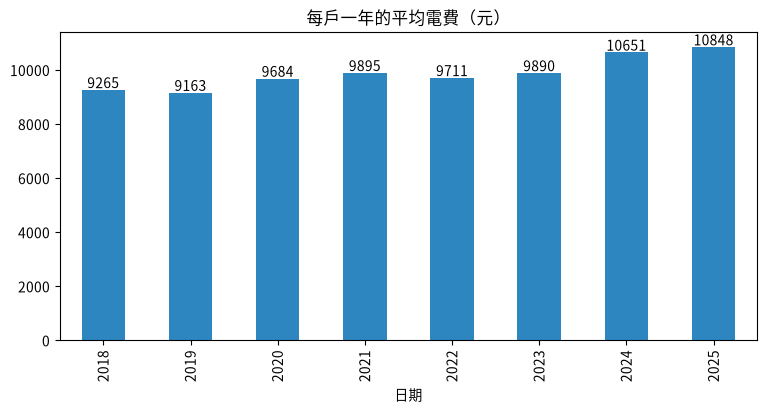

In [4]:
yearly = power['電費'].resample('YE').sum()                            # 每年加總
yearly.index = yearly.index.year
display(yearly.to_frame('一年電費(元)'))

ax = yearly.loc[2018:2025].plot.bar(figsize=(9, 4), color='#2E86C1', title='每戶一年的平均電費（元）')
ax.bar_label(ax.containers[0])
plt.show()

> 💡 **看懂結果**：2019 年每戶一年電費約 9,200 元，2025 年將近 **10,850 元**——六年漲了快 18%。2024 年那一跳特別明顯：那年台電調漲了電價。
> （2026 年還沒過完，只有到 9 月的資料，不能直接和其他年比。）

## 任務 3：今年比去年貴多少？——年增率 `pct_change(12)`

**白話說明**：月資料要比「去年同一個月」，才不會被季節影響（夏天本來就比較貴）。`pct_change(12)` 就是「跟 12 筆之前比，變化了百分之幾」。

,電費,年增率%
日期,,
2026-01-01,639,5.3
2026-02-01,616,-6.8
2026-03-01,678,-2.2
2026-04-01,657,6.0
2026-05-01,722,10.1
2026-06-01,828,8.5
2026-07-01,1137,7.6
2026-08-01,1361,9.1
2026-09-01,1398,5.0


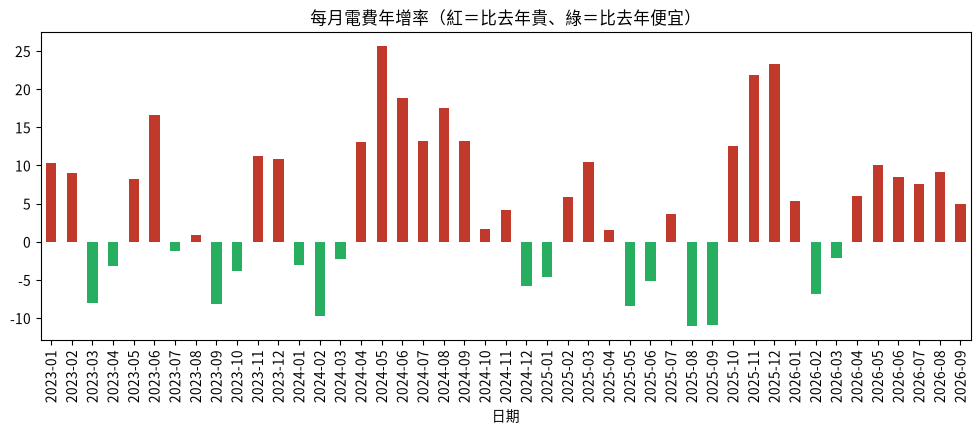

In [5]:
power['年增率%'] = (power['電費'].pct_change(12) * 100).round(1)
display(power.loc['2026', ['電費', '年增率%']])                        # 日期索引可以直接用年份字串篩選

recent = power['年增率%'].loc['2023':]
recent.index = recent.index.strftime('%Y-%m')                           # 日期 → '2023-01' 文字，長條圖的 X 軸才好讀
ax = recent.plot.bar(figsize=(12, 4), color=recent.gt(0).map({True: '#C0392B', False: '#27AE60'}),
                     title='每月電費年增率（紅＝比去年貴、綠＝比去年便宜）')
plt.show()

> 💡 **看懂結果**：2026 年 4 月以後，每個月的電費都比去年同期**貴 5～10%**。資料本身也附了「去年同期電費」欄位，你可以拿來驗算：`電費 / 去年同期電費 - 1` 應該和 `pct_change(12)` 算出來的一樣。

## 任務 4：空氣品質的「趨勢」與「異常日」——`rolling`

**白話說明**：每天的 AQI 起伏很大，很難看出趨勢。`rolling(7).mean()` 是「**7 日移動平均**」：每一天都改成「包含自己在內的 7 天平均」，線條就變平滑了。
再拿每天的值除以「前後一個月的中位數」，比值特別高的，就是**突然變差的異常日**。

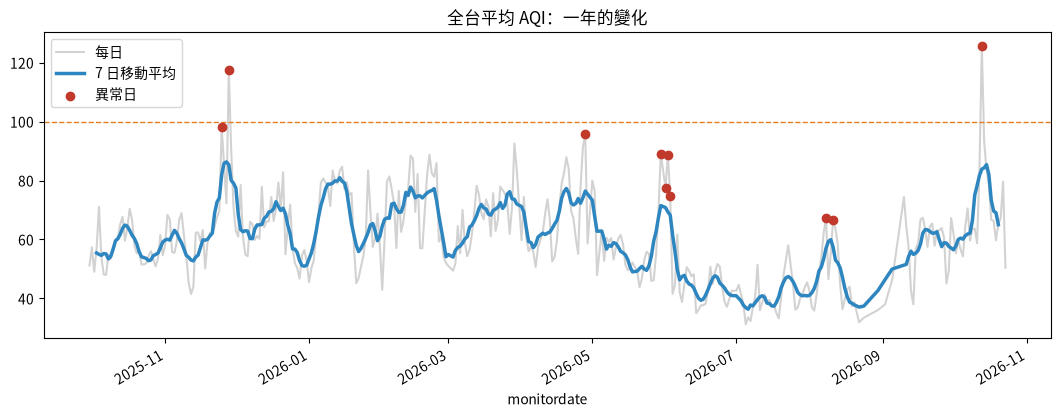

異常日：


,全台平均 AQI
monitordate,
2025-11-25,98.0
2025-11-28,117.0
2026-04-28,96.0
2026-05-30,89.0
2026-06-01,78.0
2026-06-02,89.0
2026-06-03,75.0
2026-08-08,67.0
2026-08-11,67.0


In [6]:
aqi = pd.read_csv('日空氣品質指標_近一年.csv', parse_dates=['monitordate'])
daily = aqi.groupby('monitordate')['aqi'].mean()                        # 每天、全台測站平均

smooth = daily.rolling(7, center=True).mean()                           # 7 日移動平均
normal = daily.rolling(31, center=True, min_periods=10).median()        # 前後 15 天的中位數 = 「平常」水準
abnormal = daily[daily / normal > 1.5]                                  # 比平常高 50% 以上

ax = daily.plot(figsize=(13, 4.5), alpha=0.35, color='gray', label='每日')
smooth.plot(ax=ax, color='#2E86C1', linewidth=2.5, label='7 日移動平均')
ax.scatter(abnormal.index, abnormal.values, color='#C0392B', zorder=5, label='異常日')
ax.axhline(100, color='#E67E22', linestyle='--', linewidth=1)
ax.set_title('全台平均 AQI：一年的變化'); ax.legend()
plt.show()

print('異常日：'); display(abnormal.round(0).to_frame('全台平均 AQI'))

> 💡 **看懂結果**：藍色的移動平均線清楚畫出「**冬春高、夏天低**」的季節變化；紅點是比「平常」高 50% 以上、突然變差的日子：冬天的多半是境外污染隨東北季風移入；夏天偶爾也有，常是天氣穩定、風很小，污染物散不出去的時候。

In [7]:
monthly = daily.resample('ME').mean().round(1)                           # 每月平均（ME = Month End）
monthly.index = monthly.index.strftime('%Y-%m')
monthly.to_frame('全台平均 AQI')

,全台平均 AQI
monitordate,
2025-09,51.2
2025-10,57.1
2025-11,65.4
2025-12,63.3
2026-01,67.7
2026-02,70.9
2026-03,67.4
2026-04,67.5
2026-05,57.3


## 任務 5：捷運的日期與時段——`dt` 屬性

**白話說明**：時間欄位後面加 `.dt`，就能取出各種資訊：`.dt.day_of_week`（星期幾，0 = 星期一）、`.dt.day_name()`（英文星期名）、`.dt.hour`（小時）……。這份資料的「日期」和「時段」是分開的，先組成完整的時間。

In [8]:
mrt = pd.read_csv('臺北捷運各站分時進出量_202603.csv', parse_dates=['日期'])
mrt['時間'] = mrt['日期'] + pd.to_timedelta(mrt['時段'], unit='h')         # 日期 + 幾小時 = 完整時間
mrt['星期'] = mrt['時間'].dt.day_of_week

by_weekday = mrt.groupby(mrt['時間'].dt.date)['進站人次'].sum()             # 每天的總進站人次
by_weekday.index = pd.to_datetime(by_weekday.index)
week_avg = by_weekday.groupby(by_weekday.index.day_of_week).mean().round(0)
week_avg.index = ['一', '二', '三', '四', '五', '六', '日']
week_avg.to_frame('平均每天進站人次')

,平均每天進站人次
一,2229689.0
二,2278943.0
三,2347252.0
四,2356561.0
五,2543016.0
六,2110977.0
日,1708883.0


> 💡 **看懂結果**：星期五是一週最多人搭捷運的日子（上班＋週五晚上出門玩），星期日最少。

## 任務 6：時區——國際合作夥伴要 UTC 時間

**白話說明**：電腦裡的時間如果沒有標註時區，就是「不知道是哪裡的時間」。`tz_localize('Asia/Taipei')` 是「**標註**：這是台北時間」；`tz_convert('UTC')` 是「**換算**成 UTC 時間」（台北 = UTC+8）。

In [9]:
peak = mrt.loc[mrt['進站人次'].idxmax(), ['時間', '車站', '進站人次']]
print('整個月單一小時最多人進站：', peak['車站'], peak['時間'], peak['進站人次'], '人次')

t = pd.Series([peak['時間']]).dt.tz_localize('Asia/Taipei')               # 標註：這是台北時間
print('台北時間：', t[0])
print('UTC 時間：', t.dt.tz_convert('UTC')[0])                            # 換算成 UTC（少 8 小時）
print('日本時間：', t.dt.tz_convert('Asia/Tokyo')[0])

整個月單一小時最多人進站： 台北車站 2026-03-20 18:00:00 18724 人次
台北時間： 2026-03-20 18:00:00+08:00
UTC 時間： 2026-03-20 10:00:00+00:00
日本時間： 2026-03-20 19:00:00+09:00


---

## ✍️ 換你動手：練習區

每一題都有三格：**① 半成品程式**（把 `___` 換成正確的程式）→ **② ✅ 檢查格**（自動告訴你對不對）→ **③ 🔑 參考解答**（折疊起來，先自己試）。

> 看到 `NameError: name '___' is not defined` 不用緊張，那代表還有空格沒填。

In [10]:
# @title 🧰 練習檢查小幫手（執行一次就好，不用看懂裡面的程式）
import math
import numpy as np
import pandas as pd


def _same(ans, expected, ordered=False):
    if isinstance(expected, (pd.DataFrame, pd.Series)):
        if type(ans) is not type(expected):
            return False
        try:
            assert_equal = pd.testing.assert_frame_equal if isinstance(expected, pd.DataFrame) else pd.testing.assert_series_equal
            if not ordered:
                ans, expected = ans.sort_index(), expected.sort_index()
            assert_equal(ans, expected, check_names=False, check_dtype=False,
                         check_index_type=False, check_exact=False, rtol=1e-3, atol=0.06,
                         **({'check_column_type': False} if isinstance(expected, pd.DataFrame) else {}))
            return True
        except (AssertionError, TypeError, ValueError):
            return False
    if isinstance(expected, np.ndarray):
        return np.asarray(ans).shape == expected.shape and np.allclose(np.asarray(ans, dtype=float), expected, atol=0.06)
    if isinstance(expected, (int, float, np.number)) and not isinstance(expected, bool):
        try:
            return math.isclose(float(ans), float(expected), rel_tol=1e-3, abs_tol=0.06)
        except (TypeError, ValueError):
            return False
    if isinstance(expected, (list, tuple, set)):
        return list(ans) == list(expected) if not isinstance(expected, set) else set(ans) == expected
    return ans == expected


def check(name, expected, ordered=False):
    """比對學生的變數 name 和正確答案 expected，印出 ✅ 或 ❌；ordered=True 時連排列順序也要一樣。"""
    if name not in globals():
        print(f'⏳ 還找不到變數 {name}：請先把上一格的 ___ 填好並執行')
        return
    ans = globals()[name]
    if _same(ans, expected, ordered):
        print(f'✅ {name} 答對了！')
        return
    print(f'❌ {name} 還不對，再檢查看看：')
    if type(ans) is not type(expected):
        print(f'   型態不同：你的是 {type(ans).__name__}，應該是 {type(expected).__name__}')
    elif hasattr(expected, 'shape') and getattr(ans, 'shape', None) != expected.shape:
        print(f'   大小不同：你的是 {ans.shape}，應該是 {expected.shape}')
    else:
        print('   型態和大小都對了，是數值' + ('或排列順序' if ordered else '') + '不一樣——檢查一下篩選條件或計算方式')


print('🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格')

🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格


### ✍️ 練習 1：這一年，全台空氣最差的是哪一週？

<details><summary>💡 卡住了？點我看提示</summary>

`daily.resample('W')` 把每天的 AQI 依「週」分組（週日為一週結束），`.mean()` 算每週平均，再用 `idxmax()`。

</details>

In [ ]:
# ✏️ 練習 1：把 ___ 換成正確的程式，再按執行
weekly = daily.resample(___).mean()
worst_week = weekly.idxmax()
print('最差的一週（週日結束）：', worst_week.date(), '平均 AQI', round(weekly.max(), 1))

In [ ]:
# @title ✅ 執行這格，檢查練習 1
check('worst_week', daily.resample('W').mean().idxmax())

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
weekly = daily.resample('W').mean()
worst_week = weekly.idxmax()
print('最差的一週（週日結束）：', worst_week.date(), '平均 AQI', round(weekly.max(), 1))
```

</details>

### ✍️ 練習 2：2018 年以來，電費年增率最高的是哪個月？漲了幾 %？

<details><summary>💡 卡住了？點我看提示</summary>

任務 3 已經算好 `power['年增率%']`，用 `idxmax()` 找出最大的日期，`.max()` 取出數值。

</details>

In [ ]:
# ✏️ 練習 2：把 ___ 換成正確的程式，再按執行
top_month = power['年增率%'].___()
print('年增率最高：', top_month.strftime('%Y-%m'), power['年增率%'].max(), '%')

In [ ]:
# @title ✅ 執行這格，檢查練習 2
check('top_month', power['電費'].pct_change(12).idxmax())

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
top_month = power['年增率%'].idxmax()
print('年增率最高：', top_month.strftime('%Y-%m'), power['年增率%'].max(), '%')
```

</details>

### ✍️ 練習 3：用「去年同期電費」欄位驗算年增率

<details><summary>💡 卡住了？點我看提示</summary>

年增率 = 本期 ÷ 去年同期 − 1，再乘以 100。和 `pct_change(12)` 的結果比一比，應該幾乎一樣（只有最前面 12 個月 `pct_change` 算不出來）。

</details>

In [ ]:
# ✏️ 練習 3：把 ___ 換成正確的程式，再按執行
check_yoy = ((power['電費'] / power[___] - 1) * 100).round(1)
display(pd.DataFrame({'pct_change(12)': power['年增率%'], '用去年同期欄位': check_yoy}).tail(6))

In [ ]:
# @title ✅ 執行這格，檢查練習 3
check('check_yoy', ((power['電費'] / power['去年同期電費'] - 1) * 100).round(1))

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
check_yoy = ((power['電費'] / power['去年同期電費'] - 1) * 100).round(1)
display(pd.DataFrame({'pct_change(12)': power['年增率%'], '用去年同期欄位': check_yoy}).tail(6))
```

</details>

---

## 🏆 任務完成！今天你用程式做到了這些事

- ✅ 任務 1：民國年月 `10701` → 真正的日期
- ✅ 任務 2：每戶一年要付多少電費？——`resample`
- ✅ 任務 3：今年比去年貴多少？——年增率 `pct_change(12)`
- ✅ 任務 4：空氣品質的「趨勢」與「異常日」——`rolling`
- ✅ 任務 5：捷運的日期與時段——`dt` 屬性
- ✅ 任務 6：時區——國際合作夥伴要 UTC 時間

> 🎯 **帶走一句話**：程式只是工具，真正有價值的是你從資料裡找到的那句「所以我們應該……」。
> 把上面每個 💡 **看懂結果** 用自己的話寫成一句建議，就是一份可以拿去報告的分析。